<a href="https://colab.research.google.com/github/PavelShershov/Machine_Learning/blob/main/2_CNN_Multiclass_Classification_Shershov.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа № 2. CNN — многоклассовая классификация цветов

Изменить свёрточную нейронную сеть для многоклассовой классификации изображений. Использовать набор данных Flowers из TensorFlow Datasets, содержащий пять классов цветов. Загрузить и подготовить изображения по аналогии с предыдущей работой, разделить данные на обучающую, валидационную и тестовую выборки. Добавить Data Augmentation.


In [ ]:
import os
import numpy as np

import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
import keras

from keras.models import Sequential, load_model
from keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    RandomFlip,
    RandomRotation,
    RandomZoom,
    RandomContrast,
    RandomTranslation
)
from keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

keras.utils.set_random_seed(42)

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("Доступные GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.22.0-rc1
Keras: 3.16.0.dev2026112103
Доступные GPU: []


In [ ]:
data_dir = os.path.join(os.getcwd(), "tensorflow_datasets")
os.makedirs(data_dir, exist_ok=True)

dataset_dir = os.path.join(data_dir, "tf_flowers", "3.0.1")
dataset_info_path = os.path.join(dataset_dir, "dataset_info.json")

if os.path.isdir(dataset_dir) and not os.path.isfile(dataset_info_path):
    import shutil
    shutil.rmtree(dataset_dir)

split = [
    "train[:80%]",
    "train[80%:90%]",
    "train[90%:]"
]

(train_ds_raw, validation_ds_raw, test_ds_raw), info = tfds.load(
    "tf_flowers",
    split=split,
    shuffle_files=True,
    as_supervised=True,
    with_info=True,
    data_dir=data_dir
)

class_names = info.features["label"].names
NUM_CLASSES = len(class_names)

print("Всего изображений:", info.splits["train"].num_examples)
print("Классы:", class_names)
print("Количество классов:", NUM_CLASSES)

Всего изображений: 3670
Классы: ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']
Количество классов: 5


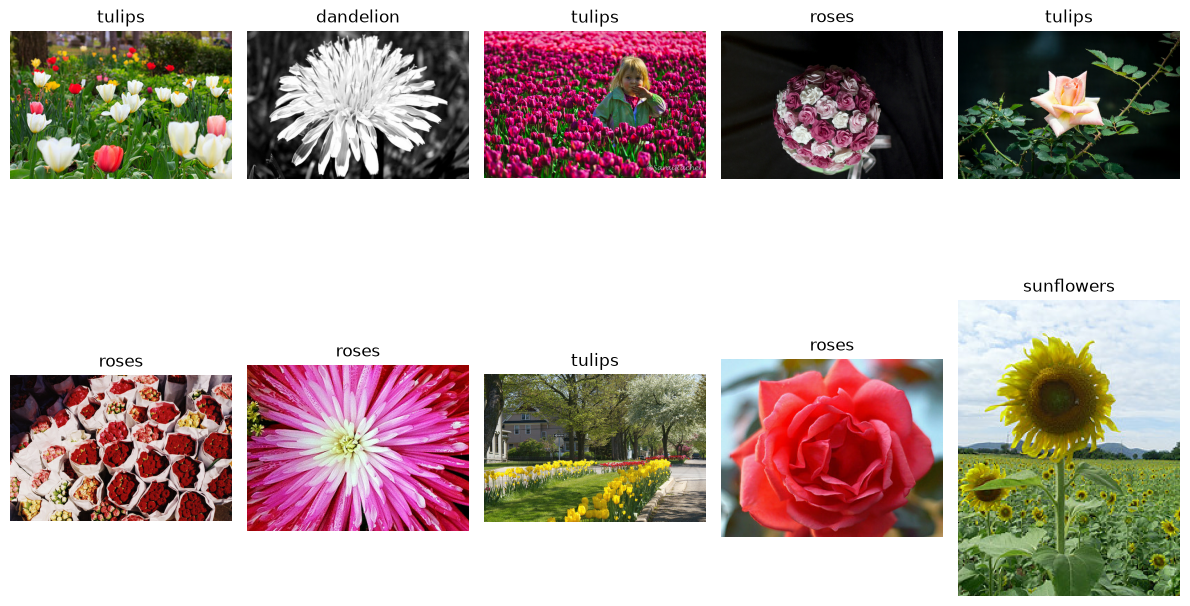

In [ ]:
plt.figure(figsize=(12, 8))

for i, (image, label) in enumerate(train_ds_raw.shuffle(1500).take(10)):
    plt.subplot(2, 5, i + 1)
    plt.imshow(image)
    plt.title(class_names[int(label.numpy())])
    plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
IMG_SIZE = 128
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE


def preprocess(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32) / 255.0
    return image, label


def prepare(data_set, shuffle=False, buffer_size=1500):
    if shuffle:
        data_set = data_set.shuffle(buffer_size=buffer_size)

    data_set = data_set.map(
        preprocess,
        num_parallel_calls=AUTOTUNE
    )
    data_set = data_set.batch(BATCH_SIZE).prefetch(AUTOTUNE)

    return data_set


train_ds, validation_ds, test_ds = [
    prepare(ds, shuffle=(i == 0))
    for i, ds in enumerate((train_ds_raw, validation_ds_raw, test_ds_raw))
]

In [ ]:
data_augmentation = Sequential(
    [
        RandomFlip("horizontal"),
        RandomRotation(0.1, interpolation="bilinear"),
        RandomZoom(0.1, interpolation="bilinear"),
        RandomContrast(0.1),
        RandomTranslation(0.1, 0.1)
    ]
)


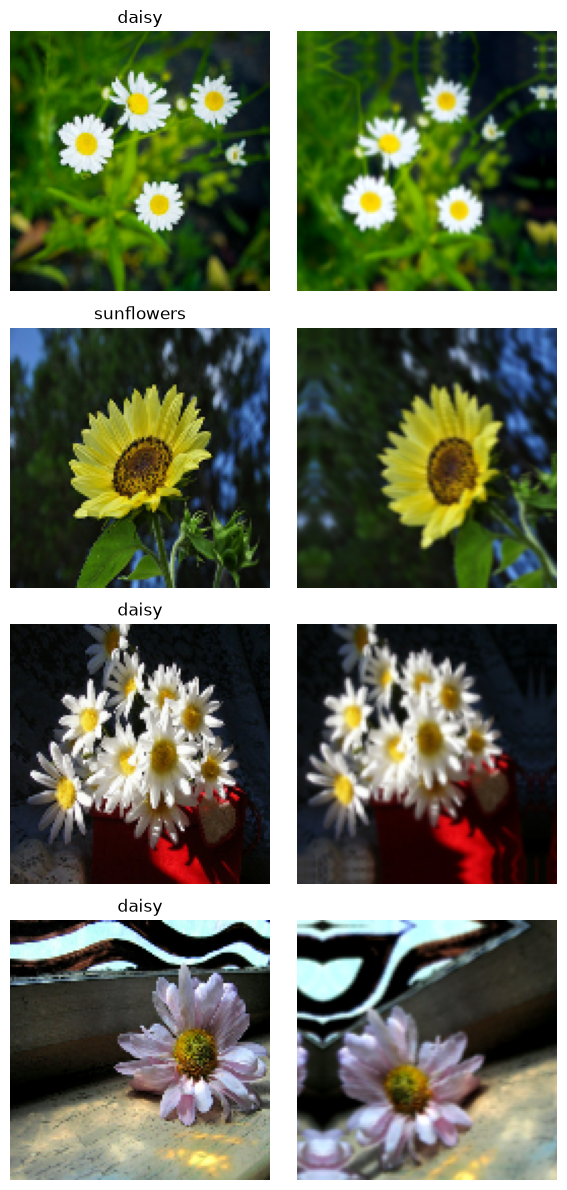

In [ ]:
images, labels = next(iter(train_ds))

plt.figure(figsize=(6, 12))

for i in range(4):
    plt.subplot(4, 2, 2 * i + 1)
    plt.imshow(images[i])
    plt.title(class_names[int(labels[i].numpy())])
    plt.axis("off")

    plt.subplot(4, 2, 2 * i + 2)
    augmented_image = data_augmentation(
        tf.expand_dims(images[i], axis=0),
        training=True
    )
    plt.imshow(tf.clip_by_value(augmented_image[0], 0.0, 1.0))
    plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
model = Sequential(
    [
        Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
        data_augmentation,

        Conv2D(32, (3, 3), activation="relu"),
        MaxPooling2D((2, 2)),

        Conv2D(64, (3, 3), activation="relu"),
        MaxPooling2D((2, 2)),

        Conv2D(128, (3, 3), activation="relu"),
        MaxPooling2D((2, 2)),

        Flatten(),
        Dense(128, activation="relu"),
        Dense(NUM_CLASSES, activation="softmax")
    ]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential (Sequential)              │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 126, 126, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 61, 61, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 30, 30, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 28, 28, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 14, 14, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 25088)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │       3,211,392 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 5)                   │             645 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,305,285 (12.61 MB)

 Trainable params: 3,305,285 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
EPOCHS = 100

model_dir = os.path.join(os.getcwd(), "Models")
os.makedirs(model_dir, exist_ok=True)

PATH = os.path.join(model_dir, "best_model_flowers.keras")

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True,
        verbose=False
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=3,
        min_lr=1e-6,
        verbose=False
    ),
    ModelCheckpoint(
        PATH,
        monitor="val_loss",
        save_best_only=True,
        verbose=False
    )
]

history = model.fit(
    train_ds,
    epochs=EPOCHS,
    validation_data=validation_ds,
    callbacks=callbacks,
    shuffle=False,
    verbose=2
)

Epoch 1/100
92/92 - 15s - 163ms/step - accuracy: 0.4584 - loss: 1.2684 - val_accuracy: 0.4905 - val_loss: 1.2764 - learning_rate: 0.0010
Epoch 2/100
92/92 - 13s - 144ms/step - accuracy: 0.5831 - loss: 1.0482 - val_accuracy: 0.6240 - val_loss: 1.0215 - learning_rate: 0.0010
Epoch 3/100
92/92 - 13s - 144ms/step - accuracy: 0.6294 - loss: 0.9438 - val_accuracy: 0.6540 - val_loss: 0.8724 - learning_rate: 0.0010
Epoch 4/100
92/92 - 13s - 144ms/step - accuracy: 0.6543 - loss: 0.8705 - val_accuracy: 0.6921 - val_loss: 0.8182 - learning_rate: 0.0010
Epoch 5/100
92/92 - 13s - 146ms/step - accuracy: 0.6843 - loss: 0.8009 - val_accuracy: 0.7030 - val_loss: 0.8201 - learning_rate: 0.0010
Epoch 6/100
92/92 - 13s - 145ms/step - accuracy: 0.6870 - loss: 0.8006 - val_accuracy: 0.6839 - val_loss: 0.9491 - learning_rate: 0.0010
Epoch 7/100
92/92 - 14s - 149ms/step - accuracy: 0.7027 - loss: 0.7665 - val_accuracy: 0.7357 - val_loss: 0.7422 - learning_rate: 0.0010
Epoch 8/100
92/92 - 14s - 149ms/step - ac

In [ ]:
loaded_model = load_model(PATH, compile=False)

loaded_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

loss, accuracy = loaded_model.evaluate(test_ds, verbose=1)

print("Test loss:", loss)
print("Test accuracy:", accuracy)


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - accuracy: 0.7629 - loss: 0.6251
Test loss: 0.6250701546669006
Test accuracy: 0.7629427909851074


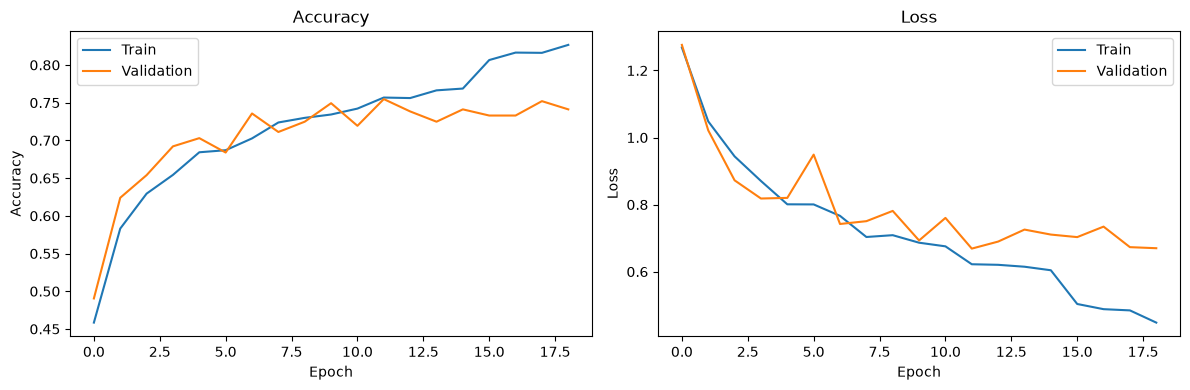

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

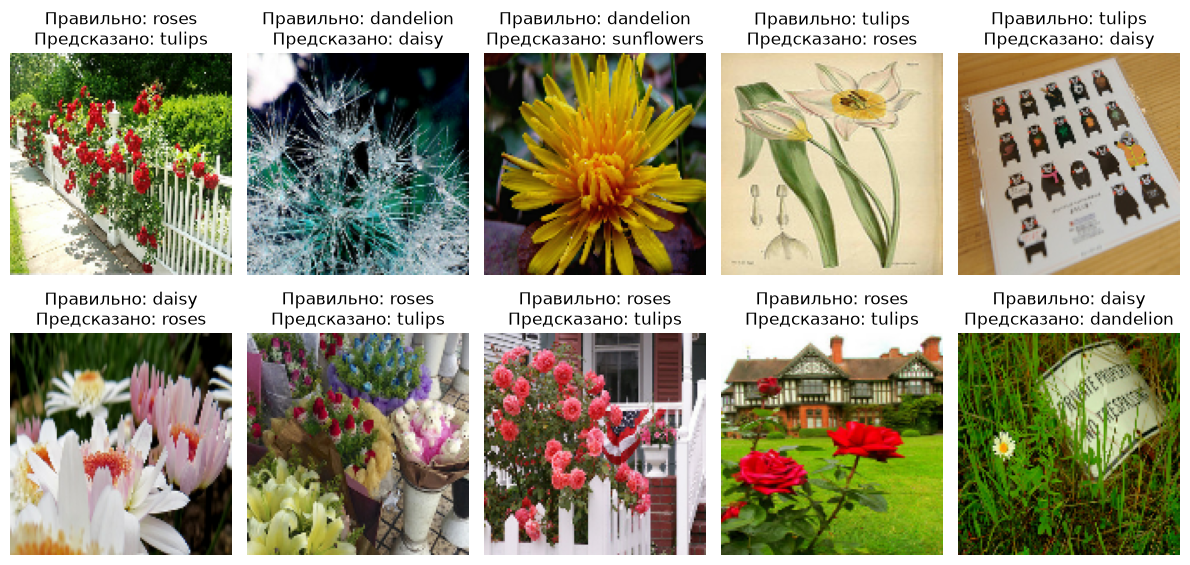

In [ ]:
wrong_images = []
wrong_labels = []
predicted_labels = []

for images, labels in test_ds:
    predictions = loaded_model.predict(images, verbose=0)
    predicted = np.argmax(predictions, axis=1)
    actual = labels.numpy()

    for image, true_label, predicted_label in zip(images.numpy(), actual, predicted):
        if true_label != predicted_label:
            wrong_images.append(image)
            wrong_labels.append(true_label)
            predicted_labels.append(predicted_label)

            if len(wrong_images) == 10:
                break

    if len(wrong_images) == 10:
        break

if wrong_images:
    columns = 5
    rows = (len(wrong_images) + columns - 1) // columns

    plt.figure(figsize=(12, 3 * rows))

    for i, (image, true_label, predicted_label) in enumerate(
        zip(wrong_images, wrong_labels, predicted_labels)
    ):
        plt.subplot(rows, columns, i + 1)
        plt.imshow(image)
        plt.title(
            f"Правильно: {class_names[true_label]}\n"
            f"Предсказано: {class_names[predicted_label]}"
        )
        plt.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("Ошибочно классифицированных изображений не найдено.")